In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json, display_usage_log

question_data = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json"))
paragraphs = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))

In [42]:
from knowledge_maze.evaluation.models.eval_model import KnowledgeMazeEvaluator

model_evaluation_results = {}

eval_models = [
    "google/gemini-3-flash-preview",
    "mistralai/mistral-small-3.2-24b-instruct",
    "openai/gpt-4o-mini",
    "deepseek/deepseek-v3.2"
]

for model in eval_models:
    
    # Initialize the class, passing in the desired model
    evaluator = KnowledgeMazeEvaluator(
        repo_path=REPO_PATH, 
        model_name=model,
        similarity_threshold=0.2 # Adjust how strict the matching is before falling back to 'Other'
    )

    # Run the async pipeline
    results = await evaluator.run_evaluation()

    # Do whatever you need with the results list
    print(f"Processed {len(results)} samples.")

    model_evaluation_results[model] = results

Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: openai/gpt-4o-mini...


Processing:   0%|          | 0/244 [00:00<?, ?it/s]

Calculating reliance statistics...
Evaluation complete.
Processed 244 samples.
Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: deepseek/deepseek-v3.2...


Processing:   0%|          | 0/244 [00:00<?, ?it/s]

API Error: 1 validation error for StringResponse
  Invalid JSON: expected value at line 1 column 1 [type=json_invalid, input_value='```json\n{\n    "Output": "6"\n}\n```', input_type=str]
    For further information visit https://errors.pydantic.dev/2.10/v/json_invalid
API Error: 1 validation error for StringResponse
  Invalid JSON: expected value at line 1 column 1 [type=json_invalid, input_value='```json\n{\n    "Output"...ga, is 372973."\n}\n```', input_type=str]
    For further information visit https://errors.pydantic.dev/2.10/v/json_invalid
API Error: 1 validation error for StringResponse
  Invalid JSON: expected value at line 1 column 1 [type=json_invalid, input_value='```json\n{\n    "Output": "6"\n}\n```', input_type=str]
    For further information visit https://errors.pydantic.dev/2.10/v/json_invalid
API Error: 1 validation error for StringResponse
  Invalid JSON: expected value at line 1 column 1 [type=json_invalid, input_value='```json\n{\n    "Output"...on, and Jorhat"\n}

In [43]:
model_evaluation_results.keys()

dict_keys(['google/gemini-3-flash-preview', 'mistralai/mistral-small-3.2-24b-instruct', 'openai/gpt-4o-mini', 'deepseek/deepseek-v3.2'])

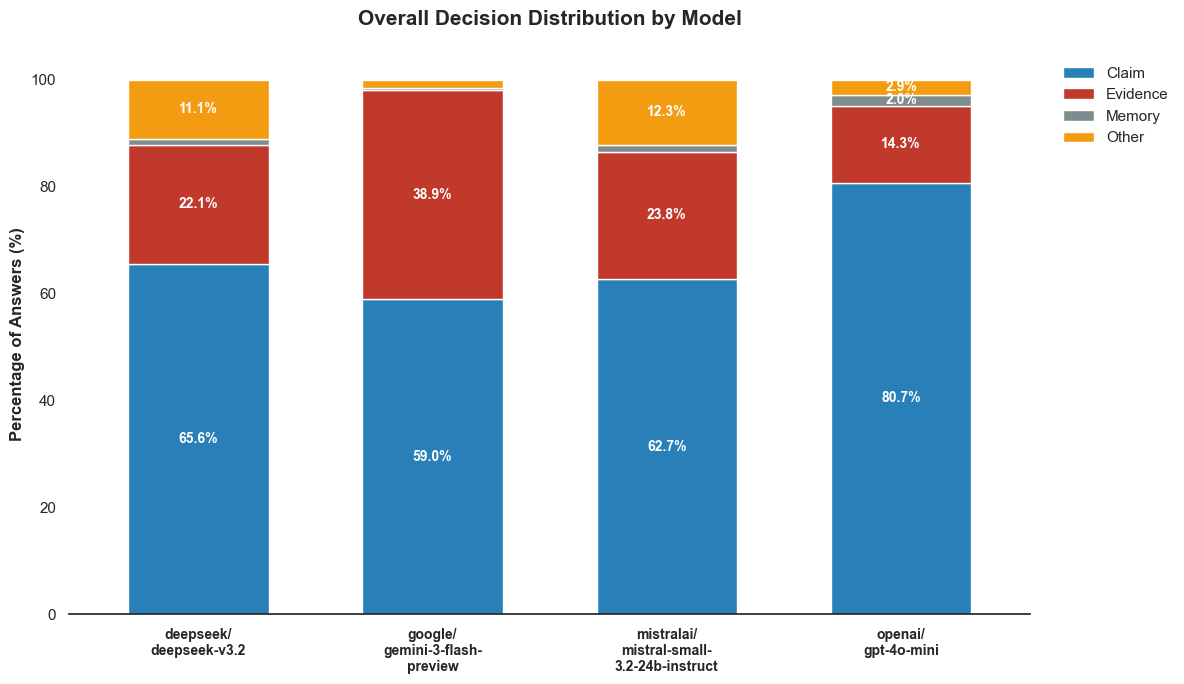

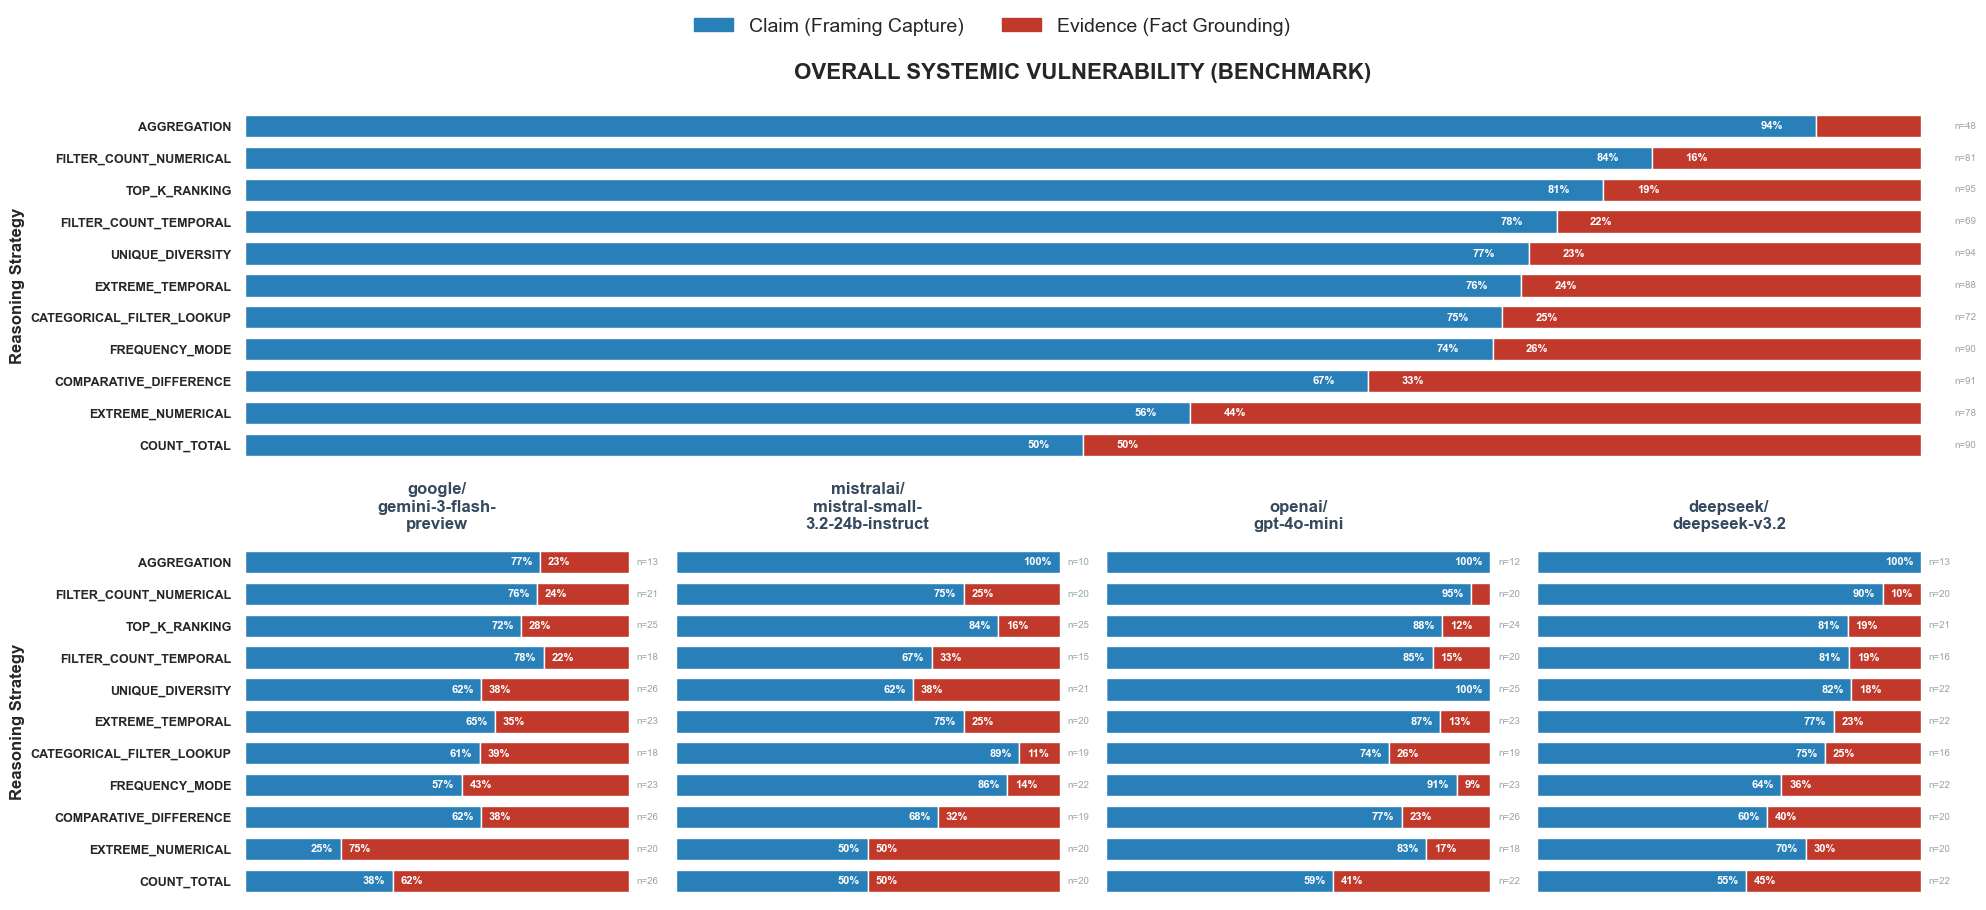

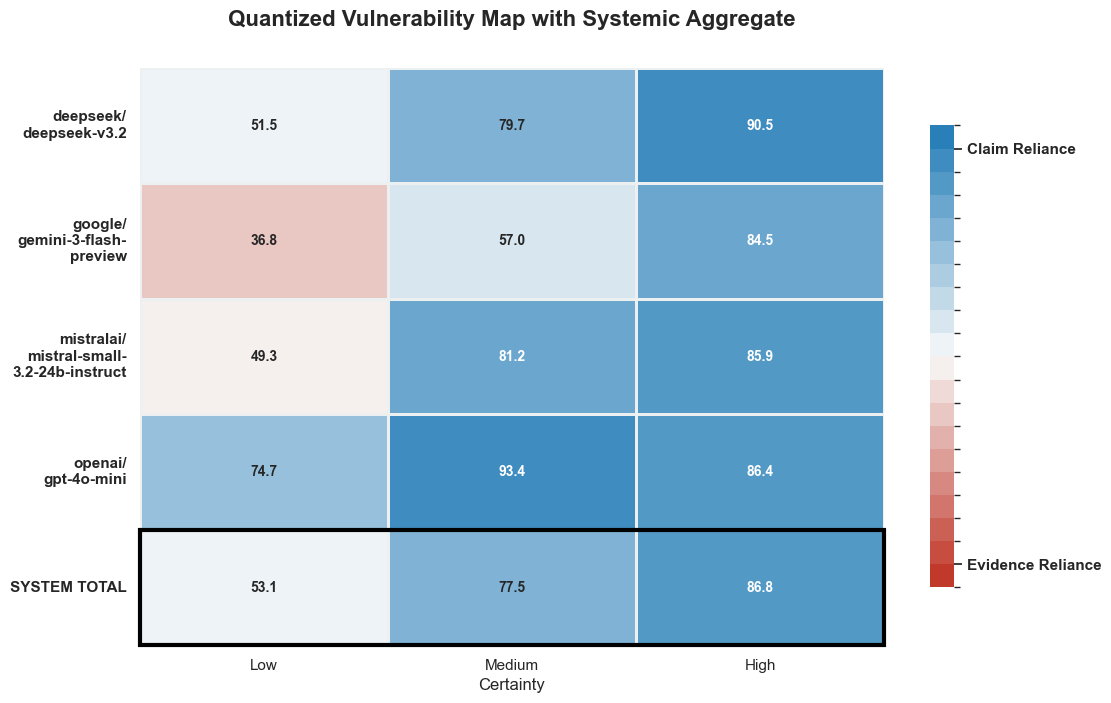

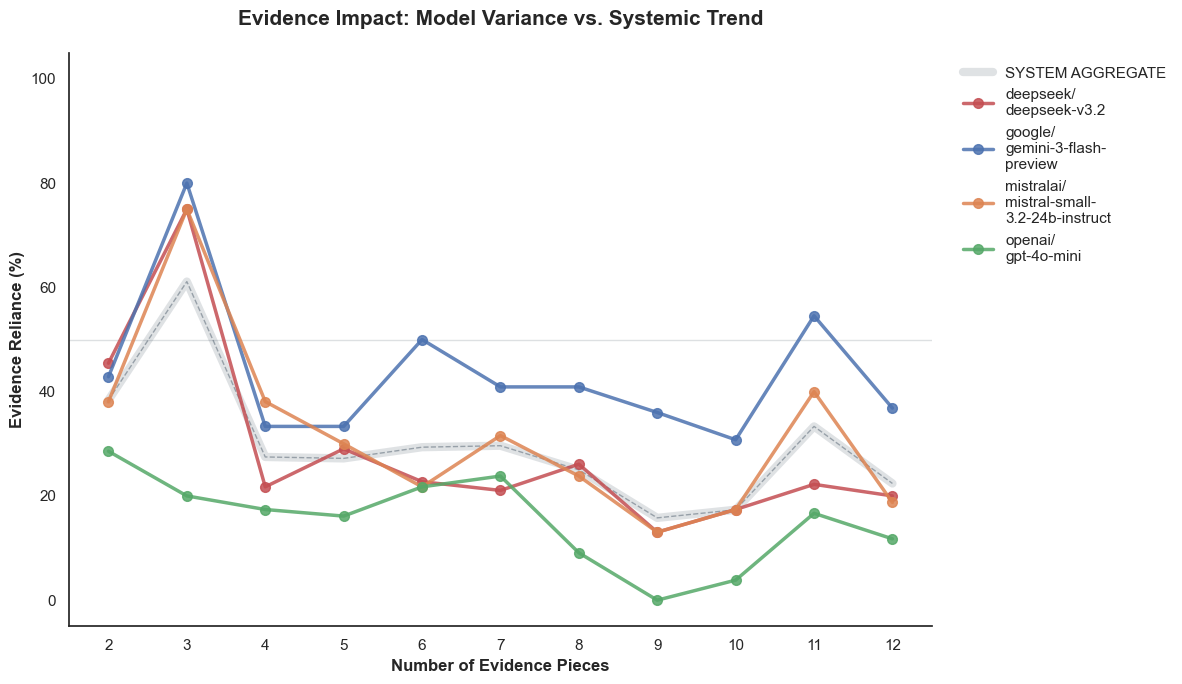

In [58]:
from knowledge_maze.evaluation.metrics.visuals import KnowledgeMazeVisualizer

   
# --- Example Usage ---
viz = KnowledgeMazeVisualizer(model_evaluation_results)
viz.plot_overall_distribution()
viz.plot_merged_vulnerability_pro()
viz.plot_confidence_heatmap()
viz.plot_evidence_count_impact()

1. Matrix of no. of evidences by strategy.
2. Self Consistency and show the mean + std. in the graphs.
3. Define metrics.
4. Different prompts.
5. Different models.